# 09 – Anwendungen: Watchlist, drei Firmen erklärt, Nutzen für Analysten

Drei Anwendungen der bisherigen Modelle. **Alle bisherigen Modelle bleiben unverändert**; für die Watchlist wird die Spezifikation B2 auf einem längeren Zeitraum neu geschätzt (ein eigenes Anwendungsmodell, keine neue Testauswertung).

- **Teil 1 – Watchlist:** Welche heute börsennotierten Firmen sehen am ehesten wie ein PE-Take-Private-Ziel aus?
- **Teil 2 – Drei Firmen erklärt:** Warum hat Modell B im Test bei drei typischen Fällen so entschieden?
- **Teil 3 – Nutzen für einen PE-Analysten:** Wie viele Firmen muss man mit dem Modell prüfen, um ein Ziel zu finden – im Vergleich zum Zufall?

## Daten und gemeinsame Bausteine (Logik wie Notebooks 03, 04, 06 und 08)

In [1]:
import ast
import time
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import shap
from pathlib import Path
from sklearn.metrics import roc_auc_score

DATA = Path("..") / "data"
panel = pd.read_csv(DATA / "processed" / "firm_year_panel.csv", dtype={"cik": str})
B_NEW = ["fcf_to_assets", "fcf_vol", "interest_coverage", "ppe_to_assets", "rd_to_assets", "cash_ratio", "altman_z2"]
ratios = pd.read_csv(DATA / "processed" / "firm_year_ratios.csv",
                     usecols=["accession", "period_end", "sales_growth_1y", "leverage", "log_assets", "float_to_book",
                              "float_to_earnings"] + B_NEW)
fund = pd.read_csv(DATA / "processed" / "firm_year_fundamentals.csv",
                   usecols=["accession", "net_income", "equity", "cash", "liabilities_current", "total_assets"])
full = (panel.merge(ratios, on="accession", validate="one_to_one")
             .merge(fund, on="accession", validate="one_to_one"))
full["roe"] = full["net_income"] / full["equity"].where(full["equity"] > 0)
full["liquidity"] = (full["cash"] - full["liabilities_current"]) / full["total_assets"].where(full["total_assets"] > 0)

# idummy: pe_main-Event (first_event_date) in derselben 2-stelligen SIC im Kalenderjahr davor
all_events = pd.read_csv(DATA / "interim" / "combined_events.csv", dtype={"cik": str})
events = all_events[all_events["sponsor_like_ptp"].astype(str) == "True"].copy()
events["event_date"] = pd.to_datetime(events["first_event_date"])
events["event_year"] = events["event_date"].dt.year
filings = pd.read_csv(DATA / "interim" / "stage_11_raw_quarters.csv", dtype={"cik": str},
                      usecols=["cik", "sic", "filed_date"]).dropna(subset=["sic"])
filings["filed_date"] = pd.to_datetime(filings["filed_date"])
f = filings.merge(events[["cik", "event_date"]], on="cik")
f["before"] = f["filed_date"] <= f["event_date"]
f["gap"] = (f["filed_date"] - f["event_date"]).abs()
f = pd.concat([f[f["before"]].sort_values("filed_date", ascending=False).groupby("cik").head(1),
               f[~f["before"]].sort_values("gap").groupby("cik").head(1)]).drop_duplicates("cik")
events = events.merge(f[["cik", "sic"]], on="cik", how="left")
active = (events.dropna(subset=["sic"]).assign(sic2=lambda e: e["sic"] // 100)
                .groupby(["sic2", "event_year"]).size().rename("n_events").reset_index())
full["sic2"] = pd.to_numeric(full["sic"], errors="coerce") // 100
full["lookup_year"] = full["fiscal_year"] - 1
full = full.merge(active.rename(columns={"event_year": "lookup_year"}), on=["sic2", "lookup_year"], how="left")
full["idummy"] = (full["n_events"].fillna(0) > 0).astype(float).where(full["sic2"].notna())
# Partnership-Kennzeichen über den Firmennamen, gleiches Muster wie Notebook 08 (Entscheidung 30.10.2026)
import re
PARTNERSHIP_PATTERN = re.compile(r"\bL\.?\s?P\.?(?=$|[\s,)/])|LIMITED PARTNERSHIP|\bPARTNERSHIP\W*$|\bMLP\b", re.I)
full["is_partnership"] = full["company_name"].str.contains(PARTNERSHIP_PATTERN)
print(f"Panel mit allen Rohwerten: {len(full):,} Zeilen, FY{full['fiscal_year'].min()}-{full['fiscal_year'].max()}")

Panel mit allen Rohwerten: 71,713 Zeilen, FY2012-2025


In [2]:
PALEPU = ["roe", "sales_growth_1y", "liquidity", "leverage", "grdummy", "idummy",
          "log_assets", "float_to_book", "float_to_earnings"]
CONTINUOUS = ["roe", "sales_growth_1y", "liquidity", "leverage", "log_assets", "float_to_book",
              "float_to_earnings"] + B_NEW

def sample_filters(d):
    """Stichprobenfilter aus Notebook 02 (ohne die Bedingung h3_observed)."""
    d = d[~d["fin_sic_60_64"].astype(bool)]
    d = d[d["completion_status"] != "uncertain"]
    d = d[~pd.to_numeric(d["sic"], errors="coerce").isin([6770])]
    return d[(d["entity_public_float"] >= 50e6) | d["first_listing_year_exempt"].astype(bool)].copy()

def add_grdummy(s):
    """grdummy mit den Jahresmedianen der Stichprobe (Regel aus Notebook 03)."""
    def high(col):
        return (s[col] > s.groupby("fiscal_year")[col].transform("median")).where(s[col].notna())
    g, l, v = high("sales_growth_1y"), high("liquidity"), high("leverage")
    combo = ((g == False) & (l == True) & (v == False)) | ((g == True) & (l == False) & (v == True))
    s["grdummy"] = combo.astype(float).where(g.notna() & l.notna() & v.notna())
    return s

def preprocess(s, est):
    """Regeln aus 04/06, alle Grenzen/Mediane/Indikatoren nur aus den Schätzzeilen `est` (Labels in Spalte y)."""
    indicators = []
    for c in PALEPU + B_NEW:
        miss = s[c].isna()
        if miss[est].mean() > 0.02 and s.loc[est & miss, "y"].sum() >= 5:
            s[f"{c}_missing"] = miss.astype(int)
            indicators.append(f"{c}_missing")
    palepu_ind = [i for i in indicators if i.replace("_missing", "") in PALEPU]
    for i in [i for i in indicators if i not in palepu_ind]:      # Entscheidung 29.10.: |rho| > 0.7 zu Palepu-Indikator
        if s.loc[est, palepu_ind].corrwith(s.loc[est, i], method="spearman").abs().max() > 0.7:
            indicators.remove(i)
            s = s.drop(columns=i)
    lo, hi = s.loc[est, CONTINUOUS].quantile(0.01), s.loc[est, CONTINUOUS].quantile(0.99)
    s[CONTINUOUS] = s[CONTINUOUS].clip(lo, hi, axis=1)
    med = s.loc[est, CONTINUOUS + ["idummy"]].median()
    s[CONTINUOUS + ["idummy"]] = s[CONTINUOUS + ["idummy"]].fillna(med)
    s["grdummy"] = s["grdummy"].fillna(0)
    s["log_assets_c"] = s["log_assets"] - s.loc[est, "log_assets"].mean()
    s["log_assets_c2"] = s["log_assets_c"] ** 2
    b_cols = PALEPU + B_NEW + indicators
    b2_cols = [("log_assets_c" if c == "log_assets" else c) for c in b_cols]
    b2_cols.insert(b2_cols.index("log_assets_c") + 1, "log_assets_c2")
    return s, b_cols, b2_cols

def fit(d, cols):
    return sm.Logit(d["y"], sm.add_constant(d[cols])).fit(
        method="newton", maxiter=200, disp=False, cov_type="cluster", cov_kwds={"groups": d["cik"]})

# Teil 1 – Watchlist

**Schätzen:** Spezifikation B2 auf **allen beobachteten Firmenjahren FY2012–2022** (`h3_observed`, Filter aus 02). Grenzen, Mediane und der Größen-Mittelwert kommen aus diesem Schätzzeitraum; die **Variablenliste ist dieselbe wie bei Modell B/B2** (Entscheidung 31.10.2026), die Indikator-Regeln werden also nicht neu angewendet. Das ist ein Anwendungsmodell: Es nutzt alle verfügbaren Daten, wird aber nicht mehr im Test ausgewertet.

**Anwenden:** auf das **jeweils neueste Firmenjahr (FY2024 oder FY2025)** aller Firmen, die die Filter aus 02 erfüllen und **noch nicht im Event-Universum** sind (`combined_events.csv`: alle 4.085 Firmen mit einer Going-Private- oder Merger-Meldung 2010–2025 – also auch bereits angekündigte Deals). Die Jahresmediane für `grdummy` kommen aus allen gefilterten Firmen des jeweiligen Jahres.

In [3]:
pop = add_grdummy(sample_filters(full))
pop["y"] = pop["y_pe_main_h3"]
est = pop["h3_observed"] & pop["fiscal_year"].between(2012, 2022)
pop, _, b2_rule = preprocess(pop, est)        # Grenzen und Mediane aus FY2012-2022

# Entscheidung 31.10.2026: dieselbe Variablenliste wie Modell B/B2 (nicht die Indikator-Regel neu anwenden).
# preprocess() wendet die Regeln auf FY2012-2022 neu an; das würde leverage_missing und fcf_vol_missing
# zusätzlich aufnehmen. Diese beiden werden hier NICHT genutzt (ihre Werte sind mit dem Median gefüllt).
B_INDICATORS = ["roe_missing", "sales_growth_1y_missing", "liquidity_missing", "grdummy_missing",
                "float_to_book_missing", "float_to_earnings_missing",
                "fcf_to_assets_missing", "interest_coverage_missing", "altman_z2_missing"]
b2_cols_w = (["roe", "sales_growth_1y", "liquidity", "leverage", "grdummy", "idummy", "log_assets_c", "log_assets_c2",
              "float_to_book", "float_to_earnings"] + B_NEW + B_INDICATORS)
print("Die Neuanwendung der Regeln hätte zusätzlich genommen:", [c for c in b2_rule if c not in b2_cols_w])
watch_model = fit(pop[est], b2_cols_w)
print(f"Schätzzeitraum FY2012-2022: {est.sum():,} Zeilen, {int(pop.loc[est, 'y'].sum())} Positive, "
      f"{pop.loc[est & (pop['y'] == 1), 'cik'].nunique()} Ziel-Firmen | konvergiert: {watch_model.mle_retvals['converged']}")
print(f"McFadden-R²: {watch_model.prsquared:.2%}")

# Kandidaten: neuestes Firmenjahr FY2024/2025, nicht im Event-Universum
cand = pop[pop["fiscal_year"].isin([2024, 2025])]
cand = cand.sort_values("fiscal_year").groupby("cik").tail(1)
in_universe = cand["cik"].isin(set(all_events["cik"]))
print(f"Firmen mit FY2024/25-Zeile nach Filtern: {len(cand):,} | davon schon im Event-Universum (ausgeschlossen): "
      f"{in_universe.sum():,} | bewertet: {(~in_universe).sum():,}")
cand = cand[~in_universe].copy()
cand["p_hat"] = watch_model.predict(sm.add_constant(cand[b2_cols_w], has_constant="add"))
print(f"FY-Verteilung der bewerteten Firmen: {cand['fiscal_year'].value_counts().to_dict()}")
print(f"Mittlere Wahrscheinlichkeit (3 Jahre): {cand['p_hat'].mean():.2%}")

Die Neuanwendung der Regeln hätte zusätzlich genommen: ['leverage_missing', 'fcf_vol_missing']


Schätzzeitraum FY2012-2022: 33,428 Zeilen, 282 Positive, 119 Ziel-Firmen | konvergiert: True
McFadden-R²: 5.74%
Firmen mit FY2024/25-Zeile nach Filtern: 2,791 | davon schon im Event-Universum (ausgeschlossen): 310 | bewertet: 2,481
FY-Verteilung der bewerteten Firmen: {2024: 2163, 2025: 318}
Mittlere Wahrscheinlichkeit (3 Jahre): 0.88%


**Beiträge der Variablen:** Koeffizient × (Wert der Firma − Median im Schätzzeitraum), in Log-Odds. Größe und Größe² werden zu einem Beitrag „Größe“ zusammengefasst. Gezeigt werden die drei Variablen, die die Wahrscheinlichkeit der Firma am stärksten **nach oben** schieben.

In [4]:
params = watch_model.params
med_est = pop.loc[est, b2_cols_w].median()

def contributions(row):
    c = {v: params[v] * (row[v] - med_est[v]) for v in b2_cols_w if v not in ("log_assets_c", "log_assets_c2")}
    c["Größe (log_assets + Quadrat)"] = (params["log_assets_c"] * (row["log_assets_c"] - med_est["log_assets_c"])
                                         + params["log_assets_c2"] * (row["log_assets_c2"] - med_est["log_assets_c"] ** 2))
    return pd.Series(c)

def make_watchlist(candidates):
    """Top 20 nach Wahrscheinlichkeit mit den drei stärksten positiven Treibern."""
    top = candidates.sort_values("p_hat", ascending=False).head(20).copy()
    contrib = top.apply(contributions, axis=1)
    top["Top-3-Treiber"] = contrib.apply(lambda r: ", ".join(f"{k} ({v:+.2f})" for k, v in r.nlargest(3).items()), axis=1)
    top["Bilanzsumme (Mio. USD)"] = (np.exp(top["log_assets"]) / 1e6).round(0)
    table = top[["company_name", "cik", "sic", "fiscal_year", "period_end", "p_hat", "Bilanzsumme (Mio. USD)", "Top-3-Treiber"]]
    table = table.rename(columns={"company_name": "Firma", "cik": "CIK", "sic": "SIC", "fiscal_year": "GJ",
                                  "period_end": "GJ-Ende", "p_hat": "Wahrscheinlichkeit (3 J.)"})
    table.index = range(1, len(table) + 1)
    return top, table

pd.set_option("display.max_colwidth", 120)
top20, watchlist = make_watchlist(cand)
print(f"Davon Partnerships (Kennzeichen is_partnership): {top20['is_partnership'].sum()} von 20")
watchlist.style.format({"Wahrscheinlichkeit (3 J.)": "{:.2%}", "SIC": "{:.0f}", "Bilanzsumme (Mio. USD)": "{:,.0f}"})

Davon Partnerships (Kennzeichen is_partnership): 13 von 20


,Firma,CIK,SIC,GJ,GJ-Ende,Wahrscheinlichkeit (3 J.),Bilanzsumme (Mio. USD),Top-3-Treiber
1,WESTLAKE CHEMICAL PARTNERS LP,0001604665,2860,2024,2024-12-31,9.01%,"1,288","float_to_book_missing (+1.51), idummy (+0.45), grdummy_missing (+0.35)"
2,"KIMBELL ROYALTY PARTNERS, LP",0001657788,1311,2024,2024-12-31,7.97%,"1,120","float_to_book_missing (+1.51), fcf_to_assets_missing (+0.24), roe_missing (+0.21)"
3,CROSSAMERICA PARTNERS LP,0001538849,5172,2024,2024-12-31,7.17%,"1,115","float_to_book_missing (+1.51), idummy (+0.45), roe_missing (+0.21)"
4,NEW ENGLAND REALTY ASSOCIATES LIMITED PARTNERSHIP,0000746514,6513,2024,2024-12-31,5.85%,394,"float_to_book_missing (+1.51), grdummy_missing (+0.35), roe_missing (+0.21)"
5,SUBURBAN PROPANE PARTNERS LP,0001005210,5900,2025,2025-09-30,5.01%,"2,296","float_to_book_missing (+1.51), idummy (+0.45), roe_missing (+0.21)"
6,"DELEK LOGISTICS PARTNERS, LP",0001552797,4610,2024,2024-12-31,4.58%,"2,042","float_to_book_missing (+1.51), roe_missing (+0.21), cash_ratio (+0.04)"
7,NGL ENERGY PARTNERS LP,0001504461,4922,2024,2025-03-31,4.58%,"4,609","float_to_book_missing (+1.51), roe_missing (+0.21), sales_growth_1y (+0.06)"
8,"STAR GROUP, L.P.",0001002590,5990,2025,2025-09-30,4.48%,937,"float_to_book_missing (+1.51), idummy (+0.45), roe_missing (+0.21)"
9,NATURAL RESOURCE PARTNERS LP,0001171486,1221,2024,2024-12-31,4.26%,773,"float_to_book_missing (+1.51), grdummy_missing (+0.35), roe_missing (+0.21)"
10,MACH NATURAL RESOURCES LP,0001980088,1311,2024,2024-12-31,4.01%,"2,338","float_to_book_missing (+1.51), roe_missing (+0.21), fcf_vol (+0.11)"


In [5]:
# Warum war fcf_vol_missing in einer früheren Version drin? Die Spearman-Regel (|rho| > 0.7 zu einem
# Palepu-Indikator) wurde auf FY2012-2022 neu angewendet - dort liegt rho knapp UNTER 0.7.
fv = pop["fcf_vol"].isna() if "fcf_vol_missing" not in pop else pop["fcf_vol_missing"]
for label, rows in [("Training Modell B, FY2012-2017", est & pop["fiscal_year"].le(2017)), ("Watchlist-Schätzung, FY2012-2022", est)]:
    rho = {i: round(pop.loc[rows, i].corr(pop.loc[rows, "fcf_vol_missing"], method="spearman"), 3)
           for i in ["sales_growth_1y_missing", "grdummy_missing"]}
    print(f"{label}: rho von fcf_vol_missing mit {rho}")
print(f"Anteil FY2012-Zeilen (dort fehlen Umsatzwachstum UND Cashflow-Historie): "
      f"{(pop.loc[est & pop['fiscal_year'].le(2017), 'fiscal_year'] == 2012).mean():.1%} (2012-17) vs. "
      f"{(pop.loc[est, 'fiscal_year'] == 2012).mean():.1%} (2012-22)")

Training Modell B, FY2012-2017: rho von fcf_vol_missing mit {'sales_growth_1y_missing': np.float64(0.702), 'grdummy_missing': np.float64(0.714)}
Watchlist-Schätzung, FY2012-2022: rho von fcf_vol_missing mit {'sales_growth_1y_missing': np.float64(0.629), 'grdummy_missing': np.float64(0.658)}
Anteil FY2012-Zeilen (dort fehlen Umsatzwachstum UND Cashflow-Historie): 16.3% (2012-17) vs. 8.8% (2012-22)


In [6]:
# Fehlend-Indikatoren des Watchlist-Modells (feste Liste wie Modell B/B2)
print([c for c in b2_cols_w if c.endswith("_missing")])
print(f"Koeffizient float_to_book_missing: {watch_model.params['float_to_book_missing']:+.3f} "
      f"(p = {watch_model.pvalues['float_to_book_missing']:.3f})")

['roe_missing', 'sales_growth_1y_missing', 'liquidity_missing', 'grdummy_missing', 'float_to_book_missing', 'float_to_earnings_missing', 'fcf_to_assets_missing', 'interest_coverage_missing', 'altman_z2_missing']
Koeffizient float_to_book_missing: +1.511 (p = 0.058)


### Prüfung bei SEC EDGAR (nur lesend)

Für jede der 20 Firmen wird die öffentliche Einreichungsliste (`data.sec.gov/submissions`) abgerufen und nach Going-Private- oder Merger-Meldungen **nach dem Geschäftsjahresende** gesucht: SC 13E3, DEFM14A, PREM14A, SC TO-T, 25-NSE (jeweils inkl. Änderungen „/A“ und der neueren Schreibweise „SCHEDULE …“). Bei 25-NSE wird zusätzlich die betroffene Wertpapierklasse ausgelesen, weil eine solche Meldung auch nur Vorzugsanteile oder Anleihen betreffen kann. Es wird nichts gespeichert; Pipeline und Daten bleiben unverändert. Die Abfrage nutzt dieselbe Absender-Kennung wie die Pipeline (die SEC verlangt eine).

In [7]:
import requests

# Absender-Kennung wie in der Pipeline: SEC_USER_AGENT aus der Umgebung oder aus .env (src/edgar_utils.py)
import sys
sys.path.insert(0, str(Path("..") / "src"))
from edgar_utils import get_user_agent
USER_AGENT = get_user_agent()
session = requests.Session()
session.headers.update({"User-Agent": USER_AGENT})

FORMS = re.compile(r"^(SC 13E3|SCHEDULE 13E-?3|DEFM14A|PREM14A|SC TO-T|SCHEDULE TO-T|25-NSE)(/A)?$")
checked_on = pd.Timestamp.today().normalize()

def edgar_check(top):
    """Nur lesend: passende Meldungen nach dem Geschäftsjahresende; bei 25-NSE die betroffene Wertpapierklasse."""
    hits = []
    for _, r in top.iterrows():
        resp = session.get(f"https://data.sec.gov/submissions/CIK{int(r['cik']):010d}.json", timeout=20)
        resp.raise_for_status()
        recent = pd.DataFrame(resp.json()["filings"]["recent"])[["form", "filingDate", "accessionNumber"]]
        recent["filingDate"] = pd.to_datetime(recent["filingDate"])
        found = recent[recent["form"].str.match(FORMS) & (recent["filingDate"] > pd.to_datetime(r["period_end"]))]
        for _, h in found.iterrows():
            hits.append({"Firma": r["company_name"], "CIK": r["cik"], "GJ-Ende": r["period_end"],
                         "Formular": h["form"], "Datum": h["filingDate"].date(), "Accession": h["accessionNumber"]})
        time.sleep(0.2)                                # SEC-Limit: höchstens 10 Abfragen pro Sekunde
    # Die Einreichungsliste enthält auch Meldungen, in denen die Firma KÄUFER ist (z. B. eigenes Übernahmeangebot).
    # Deshalb je Formular prüfen, welche Rolle die Firma hat:
    #   SC TO-T / SC 13E3: "Subject Company" im Kopf der Meldung = die Firma, um die es geht
    #   25-NSE: betroffene Wertpapierklasse (kann nur Vorzugsanteile oder Anleihen betreffen)
    #   DEFM14A / PREM14A: Proxy kann auch von der Käuferseite stammen -> manuell prüfen
    for h in hits:
        folder = f"https://www.sec.gov/Archives/edgar/data/{int(h['CIK'])}/{h['Accession'].replace('-', '')}"
        if h["Formular"].startswith("25-NSE"):
            items = session.get(f"{folder}/index.json", timeout=20).json()["directory"]["item"]
            xml = session.get(f"{folder}/{next(i['name'] for i in items if i['name'].endswith('.xml'))}", timeout=20).text
            security = re.search(r"<descriptionClassSecurity>(.*?)</descriptionClassSecurity>", xml, re.S).group(1).strip()
            h["Einordnung"] = f"Delisting von: {security}"
        elif re.match(r"(SC|SCHEDULE) (TO-T|13E)", h["Formular"]):
            header = session.get(f"{folder}/{h['Accession']}-index-headers.html", timeout=20).text
            header = re.sub(r"\s+", " ", re.sub(r"<[^>]+>", " ", header))
            subject = re.search(r"SUBJECT COMPANY:.*?COMPANY CONFORMED NAME: (.*?) CENTRAL INDEX KEY: (\d+)", header)
            if subject and int(subject.group(2)) == int(h["CIK"]):
                h["Einordnung"] = "Firma ist Zielgesellschaft"
            elif subject:
                h["Einordnung"] = f"Firma ist Bieter/Käufer, Ziel: {subject.group(1).strip()}"
            else:
                h["Einordnung"] = "manuell prüfen"
        else:
            h["Einordnung"] = "manuell prüfen (Proxy kann auch von der Käuferseite stammen)"
        time.sleep(0.2)
    real = [h for h in hits if h["Einordnung"] == "Firma ist Zielgesellschaft"]
    print(f"Davon als Zielgesellschaft bestätigt: {len(real)} Meldungen von {len({h['CIK'] for h in real})} Firmen")
    print(f"Geprüft am {checked_on.date()}: {len(top)} Firmen, {len(hits)} passende Meldungen von "
          f"{len({h['CIK'] for h in hits})} Firmen")
    return hits

hits = edgar_check(top20)
pd.DataFrame(hits) if hits else "Keine passenden Meldungen gefunden."

Davon als Zielgesellschaft bestätigt: 0 Meldungen von 0 Firmen
Geprüft am 2026-10-31: 20 Firmen, 4 passende Meldungen von 2 Firmen


,Firma,CIK,GJ-Ende,Formular,Datum,Accession,Einordnung
0,GLOBAL PARTNERS LP,0001323468,2024-12-31,25-NSE,2026-07-30,0000876661-26-000650,Delisting von: 9.50% Series B Fixed Rate Cumulative Redeemable Perpetual Preferred Units representing limited partne...
1,"APOGEE THERAPEUTICS, INC.",0001974640,2024-12-31,25-NSE,2026-09-03,0001354457-26-000853,Delisting von: Common Stock
2,"APOGEE THERAPEUTICS, INC.",0001974640,2024-12-31,DEFM14A,2026-07-13,0001140361-26-028341,manuell prüfen (Proxy kann auch von der Käuferseite stammen)
3,"APOGEE THERAPEUTICS, INC.",0001974640,2024-12-31,PREM14A,2026-07-02,0001140361-26-027469,manuell prüfen (Proxy kann auch von der Käuferseite stammen)


### Einordnung: Wie viele Treffer wären zu erwarten?

Zwischen Geschäftsjahresende und Prüfdatum liegen nur einige Monate. Zum Vergleich:
- **Zufällige 20 Firmen:** jährliche Rate × Zeitfenster. Für PE-Take-Privates die h = 1-Basisrate (pe_main), für alle Going-Privates die h = 1-Basisrate von gp_broad (näher an der Formular-Liste, die auch nicht-PE-Deals erfasst).
- **Laut Modell:** Summe der 3-Jahres-Wahrscheinlichkeiten der 20 Firmen, anteilig auf das Zeitfenster umgerechnet (vereinfachend gleichmäßig über die drei Jahre verteilt).

In [8]:
h1 = sample_filters(full)
h1 = h1[h1["h1_observed"] & h1["fiscal_year"].between(2012, 2024)]
rate_pe, rate_gp = h1["y_pe_main_h1"].mean(), h1["y_gp_broad_h1"].mean()

def expected_hits(top, hits):
    years_elapsed = ((checked_on - pd.to_datetime(top["period_end"])).dt.days / 365.25).clip(lower=0)
    print(f"Mittleres Zeitfenster seit Geschäftsjahresende: {years_elapsed.mean():.2f} Jahre | "
          f"Firmen mit passender Meldung: {len({h['CIK'] for h in hits})}")
    return pd.DataFrame({
        "erwartete Treffer": [(rate_pe * years_elapsed).sum(), (rate_gp * years_elapsed).sum(),
                              (top["p_hat"] * years_elapsed / 3).sum()],
    }, index=[f"Zufall, PE-Take-Private (Rate {rate_pe:.2%} p.a.)",
              f"Zufall, alle Going-Privates (Rate {rate_gp:.2%} p.a.)",
              "Modell (PE-Take-Private), Summe p × Zeitfenster / 3"]).round(2)

expected_hits(top20, hits)

Mittleres Zeitfenster seit Geschäftsjahresende: 1.72 Jahre | Firmen mit passender Meldung: 2


,erwartete Treffer
"Zufall, PE-Take-Private (Rate 0.29% p.a.)",0.10
"Zufall, alle Going-Privates (Rate 3.35% p.a.)",1.15
"Modell (PE-Take-Private), Summe p × Zeitfenster / 3",0.52


## Watchlist ohne Partnerships

Dasselbe Watchlist-Modell, aber Partnerships (`is_partnership`, Muster wie Notebook 08) werden aus den **Kandidaten** entfernt. Gleiche Treiber-Berechnung, gleiche EDGAR-Prüfung, gleiche Einordnung.

In [9]:
cand_np = cand[~cand["is_partnership"]]
print(f"Kandidaten ohne Partnerships: {len(cand_np):,} von {len(cand):,}")
top20_np, watchlist_np = make_watchlist(cand_np)
print(f"Neu gegenüber der ersten Liste: {(~top20_np['cik'].isin(top20['cik'])).sum()} von 20")
watchlist_np.style.format({"Wahrscheinlichkeit (3 J.)": "{:.2%}", "SIC": "{:.0f}", "Bilanzsumme (Mio. USD)": "{:,.0f}"})

Kandidaten ohne Partnerships: 2,451 von 2,481
Neu gegenüber der ersten Liste: 13 von 20


,Firma,CIK,SIC,GJ,GJ-Ende,Wahrscheinlichkeit (3 J.),Bilanzsumme (Mio. USD),Top-3-Treiber
1,AMARIN CORP PLCUK,0000897448,2834,2024,2024-12-31,3.84%,685,"idummy (+0.45), fcf_to_assets_missing (+0.24), interest_coverage (+0.22)"
2,NOVAVAX INC,0001000694,2836,2024,2024-12-31,3.57%,"1,560","idummy (+0.45), fcf_to_assets_missing (+0.24), roe_missing (+0.21)"
3,MADISON SQUARE GARDEN SPORTS CORP.,0001636519,7990,2025,2025-06-30,3.34%,"1,473","idummy (+0.45), roe_missing (+0.21), ppe_to_assets (+0.07)"
4,AMERICAN VANGUARD CORP,0000005981,2870,2024,2024-12-31,3.18%,637,"idummy (+0.45), fcf_to_assets_missing (+0.24), liquidity (+0.08)"
5,"APOGEE THERAPEUTICS, INC.",0001974640,2836,2024,2024-12-31,3.16%,754,"float_to_book_missing (+1.51), idummy (+0.45), grdummy_missing (+0.35)"
6,"CINEMARK HOLDINGS, INC.",0001385280,7830,2024,2024-12-31,3.16%,"1,040","float_to_book_missing (+1.51), grdummy_missing (+0.35), fcf_to_assets_missing (+0.24)"
7,"UPLAND SOFTWARE, INC.",0001505155,7372,2024,2024-12-31,3.10%,530,"idummy (+0.45), roe_missing (+0.21), ppe_to_assets (+0.08)"
8,NL INDUSTRIES INC,0000072162,2810,2024,2024-12-31,3.08%,578,"idummy (+0.45), grdummy_missing (+0.35), fcf_vol (+0.07)"
9,"CUSTOM TRUCK ONE SOURCE, INC.",0001709682,7359,2024,2024-12-31,3.06%,"3,502","idummy (+0.45), fcf_to_assets_missing (+0.24), liquidity (+0.06)"
10,"COMSCORE, INC.",0001158172,7389,2024,2024-12-31,3.04%,430,"idummy (+0.45), roe_missing (+0.21), fcf_vol (+0.08)"


In [10]:
hits_np = edgar_check(top20_np)
pd.DataFrame(hits_np) if hits_np else "Keine passenden Meldungen gefunden."

Davon als Zielgesellschaft bestätigt: 0 Meldungen von 0 Firmen
Geprüft am 2026-10-31: 20 Firmen, 5 passende Meldungen von 2 Firmen


,Firma,CIK,GJ-Ende,Formular,Datum,Accession,Einordnung
0,"APOGEE THERAPEUTICS, INC.",0001974640,2024-12-31,25-NSE,2026-09-03,0001354457-26-000853,Delisting von: Common Stock
1,"APOGEE THERAPEUTICS, INC.",0001974640,2024-12-31,DEFM14A,2026-07-13,0001140361-26-028341,manuell prüfen (Proxy kann auch von der Käuferseite stammen)
2,"APOGEE THERAPEUTICS, INC.",0001974640,2024-12-31,PREM14A,2026-07-02,0001140361-26-027469,manuell prüfen (Proxy kann auch von der Käuferseite stammen)
3,AURINIA PHARMACEUTICALS INC.,0001600620,2024-12-31,SC TO-T/A,2026-05-11,0001140361-26-020397,"Firma ist Bieter/Käufer, Ziel: Kezar Life Sciences, Inc."
4,AURINIA PHARMACEUTICALS INC.,0001600620,2024-12-31,SC TO-T,2026-04-13,0001140361-26-014344,"Firma ist Bieter/Käufer, Ziel: Kezar Life Sciences, Inc."


In [11]:
expected_hits(top20_np, hits_np)

Mittleres Zeitfenster seit Geschäftsjahresende: 1.74 Jahre | Firmen mit passender Meldung: 2


,erwartete Treffer
"Zufall, PE-Take-Private (Rate 0.29% p.a.)",0.10
"Zufall, alle Going-Privates (Rate 3.35% p.a.)",1.17
"Modell (PE-Take-Private), Summe p × Zeitfenster / 3",0.35


**Ergebnis Teil 1:**

- **Variablenliste:** Das Watchlist-Modell (B2 auf FY2012–2022, 33.428 Zeilen, 282 Ziele, McFadden-R² 5,7 %) nutzt **dieselbe Variablenliste wie Modell B/B2** mit 9 Fehlend-Indikatoren.
- **Warum `fcf_vol_missing` früher drin war:** Eine frühere Version hat die Indikator-Regeln auf FY2012–2022 neu angewendet und dadurch zusätzlich `leverage_missing` und `fcf_vol_missing` aufgenommen. Bei `fcf_vol_missing` liegt die Korrelation mit `grdummy_missing` bzw. `sales_growth_1y_missing` im längeren Zeitraum bei nur 0,66 bzw. 0,63 statt 0,71 bzw. 0,70. Der Grund: Das Jahr 2012, in dem Umsatzwachstum *und* Cashflow-Historie fehlen, macht dort nur 9 % statt 16 % der Zeilen aus.
- **Bewertete Firmen:** 2.481 Firmen; 310 Firmen sind schon im Event-Universum und werden ausgeschlossen.
- **Die Watchlist wird von Partnerships dominiert:** **13 der 20 Firmen sind Partnerships** (`is_partnership`). Ihr wichtigster Treiber ist `float_to_book_missing` (+1,51 Log-Odds, p = 0,06), oft zusammen mit `roe_missing`. Partnerships melden „partners' capital“ statt Eigenkapital, und Partnerships werden tatsächlich häufiger Ziel (Notebook 08). Die Liste zeigt deshalb zu einem großen Teil **die Rechtsform**, nicht nur das Finanzprofil.
- **SEC-Prüfung:** Die Prüfung ordnet jede Meldung ein, weil die SEC-Liste auch Meldungen enthält, in denen die Firma Käufer ist. **Kein PE-Treffer.**
  - Global Partners LP (25-NSE, 30.07.2026): Delisting nur der 9,50 % Series B Vorzugsanteile.
  - **Apogee Therapeutics** (PREM14A 02.07., DEFM14A 13.07., 25-NSE für die Stammaktien 03.09.2026): wurde tatsächlich übernommen und von der Börse genommen – laut Proxy (manuell gelesen am 31.10.2026) aber von **AbbVie**, also von einem strategischen Käufer, nicht von PE.
- **Erwartung:** Bei durchschnittlich 1,7 Jahren seit Geschäftsjahresende wären bei 20 zufälligen Firmen **0,1 PE-Take-Privates** und rund **1,2 Going-Privates aller Art** zu erwarten; das Modell erwartet **0,5** PE-Treffer. Beobachtet: 0 PE-Treffer und 1 Übernahme insgesamt (Apogee) – das passt zu den Erwartungen, bestätigt die Watchlist aber nicht.

**Watchlist ohne Partnerships:** Nur 30 der 2.481 bewerteten Firmen sind Partnerships, belegten aber 13 der 20 Plätze. Ohne sie rücken 13 neue Firmen nach (z. B. Comscore, Cinemark, Unisys, Herbalife, NL Industries, Kforce). Die Treiber sind jetzt vor allem `idummy` (PE-Deals in der Branche im Vorjahr), `fcf_to_assets_missing` und `roe_missing` (meist negatives Eigenkapital). Die Wahrscheinlichkeiten liegen mit 2,7–3,8 % niedriger. **SEC-Prüfung:** Apogee (siehe oben, strategischer Käufer AbbVie) und Aurinia Pharmaceuticals – dort ist Aurinia der **Bieter** für Kezar Life Sciences (SC TO-T vom 13.04.2026 und Änderung vom 11.05.2026), nicht das Ziel. Also auch hier **kein PE-Treffer**, bei erwarteten 0,1 (Zufall) bis 0,35 (Modell).

# Teil 2 – Drei Firmen erklärt (Modell B, Test 2020–2022)

Modell B exakt wie in Notebook 06 (Kontrolle: Test-AUC 0,698).

**Auswahlregel (jeweils der extremste Fall):**
- **(a) Treffer:** echtes Ziel (y = 1) mit der **höchsten** vorhergesagten Wahrscheinlichkeit.
- **(b) Verpasst:** echtes Ziel mit der **niedrigsten** vorhergesagten Wahrscheinlichkeit.
- **(c) Fehlalarm:** Nicht-Ziel mit der **höchsten** Wahrscheinlichkeit, und zwar nur unter Firmen, die im gesamten Datensatz **auf keinem Weg** privat gingen (`gp_broad` = 0 für die Firma) – damit es wirklich ein Fehlalarm ist und nicht etwa ein Take-Private durch einen anderen Käufer.

**Beiträge:** Koeffizient × (Wert − Trainingsmittelwert) in Log-Odds. Für ein Logit ist das genau der SHAP-Wert des LinearExplainers (bei unabhängigen Variablen). Startpunkt der Grafik ist die Vorhersage für eine „Durchschnittsfirma“, Endpunkt die Vorhersage für die Firma.

In [12]:
main = add_grdummy(sample_filters(full[full["h3_observed"]]))
main["y"] = main["y_pe_main_h3"]
main["split"] = np.where(main["fiscal_year"] <= 2017, "train", np.where(main["fiscal_year"] >= 2020, "test", "embargo"))
main, b_cols, _ = preprocess(main, main["split"] == "train")
tr, te = main[main["split"] == "train"], main[main["split"] == "test"].copy()
res_b = fit(tr, b_cols)
te["p_hat"] = res_b.predict(sm.add_constant(te[b_cols], has_constant="add"))
te["Rang"] = te["p_hat"].rank(ascending=False, method="first").astype(int)
print(f"Kontrolle Modell B: Test-AUC {roc_auc_score(te['y'], te['p_hat']):.3f} (Notebook 06: 0.698) | Testzeilen {len(te):,}")

firm_went_private = main.groupby("cik")["gp_broad"].max().astype(bool)
cases = {
    "(a) Treffer": te[te["y"] == 1].sort_values("p_hat", ascending=False).iloc[0],
    "(b) Verpasst": te[te["y"] == 1].sort_values("p_hat").iloc[0],
    "(c) Fehlalarm": te[(te["y"] == 0) & ~te["cik"].map(firm_went_private)].sort_values("p_hat", ascending=False).iloc[0],
}
pd.DataFrame({k: {"Firma": r["company_name"], "CIK": r["cik"], "SIC": int(r["sic"]), "GJ": int(r["fiscal_year"]),
                  "Wahrscheinlichkeit": f"{r['p_hat']:.2%}", "Rang im Test": f"{r['Rang']:,} von {len(te):,}",
                  "Bilanzsumme (Mio. USD)": f"{np.exp(r['log_assets']) / 1e6:,.0f}"} for k, r in cases.items()}).T

Kontrolle Modell B: Test-AUC 0.698 (Notebook 06: 0.698) | Testzeilen 9,596


,Firma,CIK,SIC,GJ,Wahrscheinlichkeit,Rang im Test,Bilanzsumme (Mio. USD)
(a) Treffer,"ENDEAVOR GROUP HOLDINGS, INC.",0001766363,7900,2022,5.39%,"19 von 9,596","12,504"
(b) Verpasst,"GREENLIGHT BIOSCIENCES HOLDINGS, PBC",0001822691,2836,2022,0.02%,"9,464 von 9,596",149
(c) Fehlalarm,"CYPRESS ENVIRONMENTAL PARTNERS, L.P.",0001587246,7389,2020,13.37%,"1 von 9,596",120


Startpunkt (Durchschnittsfirma): 0.59%


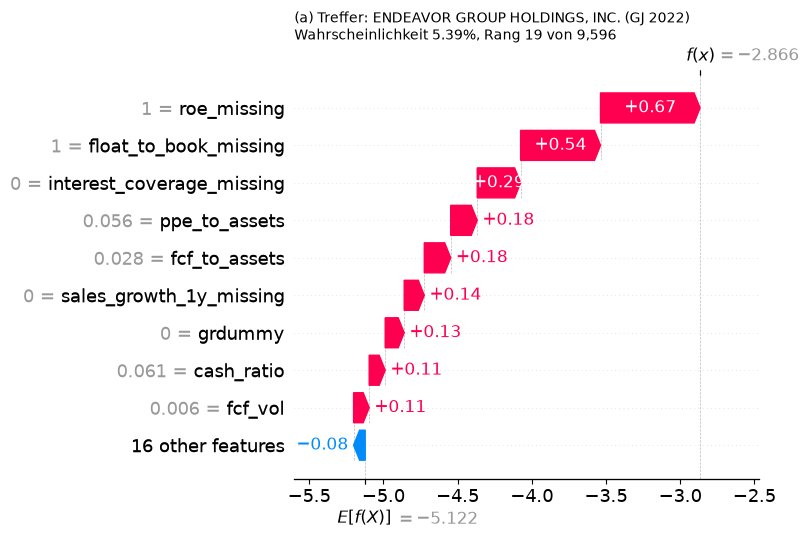

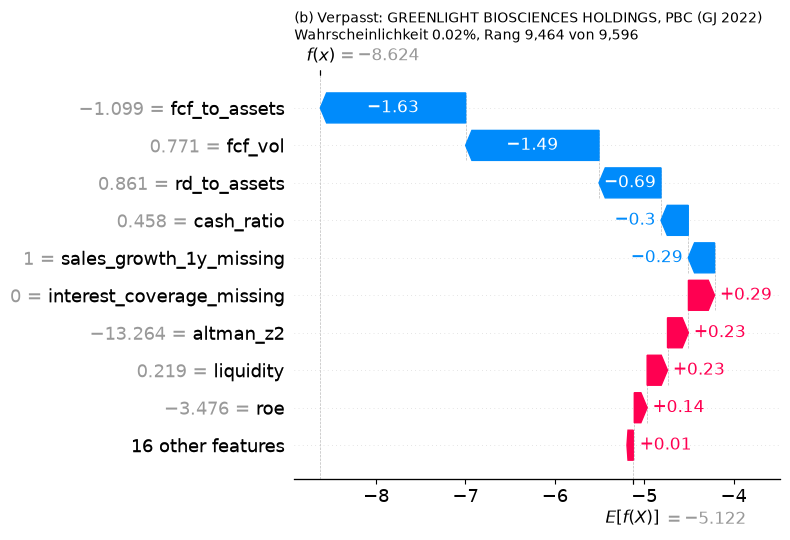

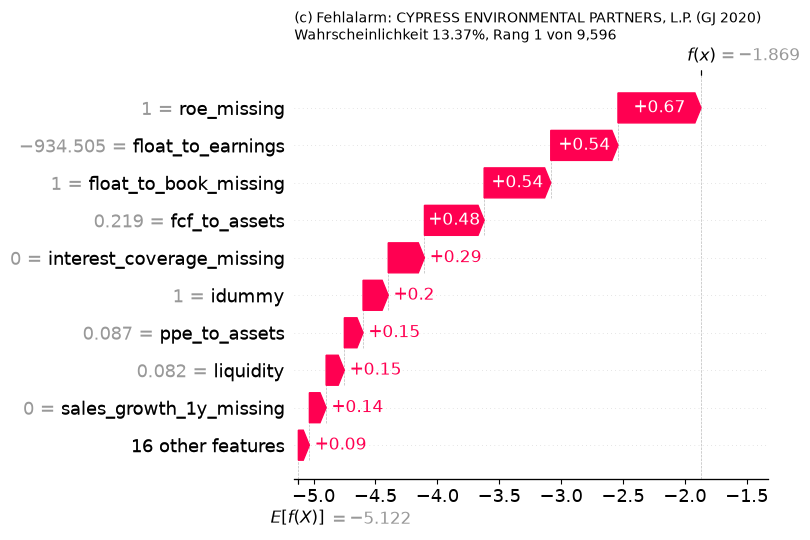

,(a) Treffer,(b) Verpasst,(c) Fehlalarm
roe_missing,0.671,NaN,0.671
float_to_book_missing,0.538,NaN,0.538
interest_coverage_missing,0.292,0.292,0.292
ppe_to_assets,0.179,NaN,NaN
fcf_to_assets,0.178,-1.626,0.482
sales_growth_1y_missing,0.135,-0.294,NaN
fcf_vol,NaN,-1.492,NaN
rd_to_assets,NaN,-0.694,NaN
cash_ratio,NaN,-0.305,NaN
float_to_earnings,NaN,NaN,0.543


In [13]:
mean_tr = tr[b_cols].mean()
base_logodds = res_b.params["const"] + (res_b.params[b_cols] * mean_tr).sum()
print(f"Startpunkt (Durchschnittsfirma): {1 / (1 + np.exp(-base_logodds)):.2%}")

def explain(row):
    return pd.Series(res_b.params[b_cols].to_numpy() * (row[b_cols].astype(float).to_numpy() - mean_tr.to_numpy()), index=b_cols)

case_contrib = {}
for name, row in cases.items():
    contrib = explain(row)
    case_contrib[name] = contrib
    exp = shap.Explanation(values=contrib.to_numpy(), base_values=base_logodds,
                           data=row[b_cols].astype(float).round(3).to_numpy(), feature_names=b_cols)
    shap.plots.waterfall(exp, max_display=10, show=False)
    plt.title(f"{name}: {row['company_name']} (GJ {int(row['fiscal_year'])})\n"
              f"Wahrscheinlichkeit {row['p_hat']:.2%}, Rang {row['Rang']:,} von {len(te):,}", loc="left", fontsize=10)
    plt.gcf().set_size_inches(8, 5.5)
    plt.tight_layout()
    plt.show()

pd.DataFrame({k: v.reindex(v.abs().sort_values(ascending=False).index[:6]).round(3).to_dict() for k, v in case_contrib.items()})

**Ergebnis Teil 2:**

**(a) Treffer – Endeavor Group Holdings (GJ 2022, Rang 19 von 9.596, 5,4 %).** Endeavor wurde 2024 von Silver Lake privat genommen (laut Event-Daten angekündigt am 05.08.2024). Am stärksten erhöhen die Wahrscheinlichkeit zwei Lücken: Die Eigenkapitalrendite und das Kurs-Buchwert-Verhältnis fehlen in den Daten (+0,67 und +0,54). Dazu kommen ein vorhandener Zinsaufwand, positiver freier Cashflow und wenige Sachanlagen. Vorsicht: Die beiden größten Beiträge stammen von Indikatoren, die im Modell nicht signifikant sind – der „Treffer“ beruht also teilweise auf einer Datenlücke.

**(b) Verpasst – GreenLight Biosciences (GJ 2022, Rang 9.464 von 9.596, 0,02 %).** GreenLight wurde 2023 vom Fall Line Endurance Fund übernommen. Das Modell hielt die Firma für äußerst unwahrscheinlich, weil sie stark Geld verbrannte: sehr negativer freier Cashflow (−1,63), stark schwankender Cashflow (−1,49) und hohe F&E-Ausgaben (−0,69). Solche Biotech-Firmen sind in den Trainingsdaten fast nie PE-Ziele; dieser Deal war für das Modell ein untypischer Ausreißer.

**(c) Fehlalarm – Cypress Environmental Partners (GJ 2020, Rang 1 von 9.596, 13,4 %).** Die Firma ging im Datensatz auf keinem Weg privat, bekam aber die höchste Wahrscheinlichkeit im ganzen Test. Es ist eine Partnership: Eigenkapitalrendite und Kurs-Buchwert-Verhältnis fehlen (+0,67, +0,54). Dazu kommen ein auffälliges Kurs-Gewinn-Verhältnis (+0,54), positiver freier Cashflow (+0,48) und PE-Aktivität in der Branche im Vorjahr (+0,20). Das ist dasselbe Muster wie in der Watchlist: Die Rechtsform „Partnership“ treibt die Vorhersage über die Datenlücke nach oben.

# Teil 3 – Nutzen für einen PE-Analysten (Modell B, Test 2020–2022)

Ein Analyst sortiert alle börsennotierten Firmenjahre nach der Modell-Wahrscheinlichkeit und prüft von oben nach unten. Wie viele echte Ziele findet er in den obersten 1 %, 5 %, 10 % und 20 %? **Firmen pro gefundenem Ziel** = geprüfte Firmenjahre / gefundene Ziele. Zufall: 1 / Basisrate.

In [14]:
n_all, n_pos = len(te), int(te["y"].sum())
random_per_hit = n_all / n_pos
ranked = te.sort_values("p_hat", ascending=False)
rows = []
for share in [0.01, 0.05, 0.10, 0.20]:
    k = int(np.ceil(share * n_all))
    found = int(ranked["y"].iloc[:k].sum())
    per_hit = k / found if found else np.nan
    rows.append({"oberste": f"{share:.0%}", "geprüft (Firmenjahre)": k, "echte Ziele gefunden": found,
                 "Anteil aller Ziele": f"{found / n_pos:.0%}",
                 "Firmen pro gefundenem Ziel": round(per_hit, 1), "Zufall: Firmen pro Ziel": round(random_per_hit, 1),
                 "Faktor besser als Zufall": round(random_per_hit / per_hit, 2) if found else np.nan,
                 "In Analystensprache": (f"Wer die obersten {share:.0%} ({k:,} Firmenjahre) prüft, findet {found} von {n_pos} Zielen – "
                                         f"mit dem Modell jedes {per_hit:.0f}. Mal ein Ziel, zufällig jedes {random_per_hit:.0f}. Mal.")
                                        if found else f"In den obersten {share:.0%} ({k:,} Firmenjahre) ist kein Ziel."})
print(f"Testzeitraum: {n_all:,} Firmenjahre, {n_pos} Ziele, Basisrate {n_pos / n_all:.2%} -> zufällig jedes {random_per_hit:.0f}. Firmenjahr")
analyst = pd.DataFrame(rows).set_index("oberste")
analyst

Testzeitraum: 9,596 Firmenjahre, 70 Ziele, Basisrate 0.73% -> zufällig jedes 137. Firmenjahr


,geprüft (Firmenjahre),echte Ziele gefunden,Anteil aller Ziele,Firmen pro gefundenem Ziel,Zufall: Firmen pro Ziel,Faktor besser als Zufall,In Analystensprache
oberste,,,,,,,
1%,96,3,4%,32.0,137.1,4.28,"Wer die obersten 1% (96 Firmenjahre) prüft, findet 3 von 70 Zielen – mit dem Modell jedes 32. Mal ein Ziel, zufällig..."
5%,480,9,13%,53.3,137.1,2.57,"Wer die obersten 5% (480 Firmenjahre) prüft, findet 9 von 70 Zielen – mit dem Modell jedes 53. Mal ein Ziel, zufälli..."
10%,960,18,26%,53.3,137.1,2.57,"Wer die obersten 10% (960 Firmenjahre) prüft, findet 18 von 70 Zielen – mit dem Modell jedes 53. Mal ein Ziel, zufäl..."
20%,1920,30,43%,64.0,137.1,2.14,"Wer die obersten 20% (1,920 Firmenjahre) prüft, findet 30 von 70 Zielen – mit dem Modell jedes 64. Mal ein Ziel, zuf..."


In [15]:
for s in analyst["In Analystensprache"]:
    print("•", s)

• Wer die obersten 1% (96 Firmenjahre) prüft, findet 3 von 70 Zielen – mit dem Modell jedes 32. Mal ein Ziel, zufällig jedes 137. Mal.
• Wer die obersten 5% (480 Firmenjahre) prüft, findet 9 von 70 Zielen – mit dem Modell jedes 53. Mal ein Ziel, zufällig jedes 137. Mal.
• Wer die obersten 10% (960 Firmenjahre) prüft, findet 18 von 70 Zielen – mit dem Modell jedes 53. Mal ein Ziel, zufällig jedes 137. Mal.
• Wer die obersten 20% (1,920 Firmenjahre) prüft, findet 30 von 70 Zielen – mit dem Modell jedes 64. Mal ein Ziel, zufällig jedes 137. Mal.


**Ergebnis Teil 3:** Zufällig ist im Test jedes **137.** Firmenjahr ein Ziel. Mit der Modell-Rangliste sieht es so aus:

- **Oberste 1 %:** jedes **32.** Firmenjahr ein Ziel, 4,3-mal besser als Zufall – aber das sind nur 3 der 70 Ziele.
- **Oberste 5 % und 10 %:** jedes **53.** Firmenjahr, 2,6-mal besser.
- **Oberste 20 %:** jedes **64.** Firmenjahr; damit findet man 30 der 70 Ziele (43 %).

Für einen Analysten heißt das: Das Modell verengt die Suche spürbar, aber auch in der besten Gruppe bleiben über 30 Firmen pro gefundenem Ziel. Es eignet sich als Vorfilter, nicht als Vorhersage einzelner Deals.

## Kernergebnisse

1. **Watchlist:** Die 20 aktuell wahrscheinlichsten Ziele sind zu 65 % Partnerships. Ihr Rang kommt vor allem daher, dass ihr Eigenkapital in den Daten fehlt – die Liste zeigt also stark die Rechtsform, weniger ein echtes PE-Profil.
2. **SEC-Prüfung:** In keiner der beiden Listen gibt es seit Geschäftsjahresende ein PE-Take-Private; eine Firma (Apogee Therapeutics) wurde übernommen, aber von AbbVie, einem strategischen Käufer. Bei erwarteten 0,1 (Zufall) bis 0,5 (Modell) PE-Treffern ist das kein Widerspruch, aber auch keine Bestätigung.
3. **Drei Fälle:** Das Modell erkennt Ziele mit Cashflow und vorhandener Zinslast (Endeavor), übersieht geldverbrennende Biotech-Übernahmen (GreenLight) und schlägt bei Partnerships wegen fehlender Eigenkapital-Daten Fehlalarm (Cypress Environmental).
4. **Nutzen für Analysten:** In den obersten 1–10 % der Rangliste findet man jedes 32. bis 53. Mal ein Ziel statt zufällig jedes 137. Mal – eine 2,6- bis 4,3-fache Verbesserung.
5. **Wichtigste Konsequenz:** Die Behandlung fehlender Eigenkapital-Werte bei Partnerships ist die größte Schwachstelle im praktischen Einsatz und gehört als Limitation in die Arbeit.